# Benchmarking

This notebook summarizes all the benchmarking cases available in PyWake to this date.

Three different scenarios are considered: Single Wake cases, Wind Farm cases and Farm-to-Farm interaction. In the Single Wake cases, the normalized velocity deficit behind a turbine is computed for different wind directions at various downstream distances. In addition, a case with stability in neutral, stable and unstable atmosphere is also included. For the Wind Farm cases, the wind farms Lillgrund and Hornsrev1 are used to calculate the power efficiency in a specific row of turbines within the wind farm, as well as the total wind farm efficiency. Lastly, the Farm-to-Farm interaction case studies the wind farm cluster of Nysted and Rødsand II and the effects of the Nysted wind farm over Rødsand II's efficiency are investigated.

For all cases, the data is represented by measurements either from masts, lidar or SCADA data, depending on the case. Furthermore, RANS simulations are given by CFD runs from PyWake Ellipsys, and in some cases, LES data is also available.

The aim of the study is to compare the given data and CFD with PyWake's engineering wind farm models. The engineering models used in the benchmark follow the literature setup, and can be found in the [Predefined WindFarm Models](EngineeringWindFarmModels.ipynb#Predefined-WindFarmModels) notebook. So far, the models included are:

- Jensen_1983
- Bastankhah_PorteAgel_2014
- Niayifar_PorteAgel_2016
- Zong_PorteAgel_2020
- Blondel_Cathelain_2020
- Nygaard_2022
- Ott_Nielsen_2014

However, the study can be expanded to include more wind farm models as they become available in PyWake.

For more information about the sites included in the benchmark as well as their configuration can be found in [PyWake Ellipsys' examples](https://topfarm.pages.windenergy.dtu.dk/cuttingedge/pywake/pywake_ellipsys/master/examples.html).

**Install PyWake if needed**

In [1]:
try:
    import py_wake
except ModuleNotFoundError:
    !pip install git+https://gitlab.windenergy.dtu.dk/TOPFARM/PyWake.git
    import py_wake

**Now we import some basic Python and PyWake elements**

In [2]:
import numpy as np
import matplotlib.style
%matplotlib inline
import matplotlib.pyplot as plt
import os
import warnings

warnings.filterwarnings("ignore")

In [3]:
# Parameters for plot
matplotlib.style.use('classic')
# Latex font
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams["figure.titlesize"] = 'x-large'
# Path for FUGA LUTs
lut_path = os.path.dirname(py_wake.__file__) + '/validation/benchmark/fuga_files'

**Setting up the list containing the user-defined wind farm models for the study**

In [4]:
# engineering wind farm models
from py_wake.literature.noj import Jensen_1983
from py_wake.literature.gaussian_models import Bastankhah_PorteAgel_2014
from py_wake.literature.fuga import Ott_Nielsen_2014
from py_wake.literature.fuga import Ott_Nielsen_2014_Blockage
from py_wake.literature.gaussian_models import Niayifar_PorteAgel_2016
from py_wake.literature.gaussian_models import Zong_PorteAgel_2020
from py_wake.literature.gaussian_models import Blondel_Cathelain_2020
from py_wake.literature.cumulative_sum import CumulativeWake
from py_wake.literature.turbopark import Nygaard_2022

In [5]:
wffms = {Jensen_1983: {'label': 'NOJ', 'color': 'deepskyblue'},
         Niayifar_PorteAgel_2016: {'label': 'NIAY', 'color': 'brown'},
         # Zong_PorteAgel_2020:{'label':'ZONG', 'color':'lime'},
         Bastankhah_PorteAgel_2014: {'label': 'GAU', 'color': 'r'},
         # Ott_Nielsen_2014:{'label':'FUGA', 'color':'y'},
         Blondel_Cathelain_2020: {'label': 'SUPG', 'color': 'b'},
         Nygaard_2022: {'label': 'TURBOG', 'color': 'purple'},
         CumulativeWake: {'label': 'CGAU', 'color': 'coral'}
         }
cLES = 'c'
cRANS = 'g'

## Single Wake Cases
---

The Single Wake cases studied in the benchmark correspond to:
    
| Name | $U_0$ (m/s)  | $C_T$ (-) | $TI$ (%) | $D$ (m) | $z_H$ (m) |
| :--- | :--- | :--- | :--- | :--- | :--- |
| Wieringermeer-West | 10.7 | 0.63 | 8.0 | 80.0 | 80.0
| Wieringermeer-East | 10.9 | 0.63 | 6.0 | 80.0 | 80.0
| Nibe | 8.5 | 0.89 | 8.0 | 40.0 | 45.0
| Nordtank-500 | 7.45 | 0.70 | 11.2 | 41.0 | 36.0
| NREL-5MW_TIlow | 8.0 | 0.79 | 4.0 | 126.0 | 90.0
| NREL-5MW_TIhigh | 8.0 | 0.79 | 12.8 | 126.0 | 90.0

In [6]:
path_wieringermeer_west = lut_path + '/Wieringermeer_West/LUTs_Zeta0=0.00e+00_8_32_D80_zhub80_zi400_z0=0.00030000_z80.0_UL_nx2048_ny512_dx20.0_dy5.0.nc'
path_wieringermeer_east = lut_path + '/Wieringermeer_East/LUTs_Zeta0=0.00e+00_8_32_D80_zhub80_zi400_z0=0.00005000_z80.0_UL_nx2048_ny512_dx20.0_dy5.0.nc'
path_nibe = lut_path + '/Nibe/LUTs_Zeta0=0.00e+00_8_32_D40_zhub45_zi400_z0=0.00016000_z45.0_UL_nx2048_ny512_dx10.0_dy2.5.nc'
path_nordtank = lut_path + '/Nordtank_500/LUTs_Zeta0=0.00e+00_8_32_D41_zhub36_zi400_z0=0.00470000_z36.0_UL_nx2048_ny512_dx10.25_dy2.5625.nc'
path_nrelhighTI = lut_path + '/NREL5MW_HighTI/LUTs_Zeta0=0.00e+00_8_32_D126_zhub90_zi400_z0=0.03640000_z90.0_UL_nx2048_ny512_dx31.5_dy7.875.nc'
path_nrellowTI = lut_path + '/NREL5MW_LowTI/LUTs_Zeta0=0.00e+00_8_32_D126_zhub90_zi400_z0=0.00001000_z90.0_UL_nx2048_ny512_dx31.5_dy7.875.nc'

# Defining the dictionary containing all of the cases and their setup

SingleWakeCases = [
    {'name': 'Wieringermeer-West', 'U0': 10.7, 'CT': 0.63, 'TItot': 0.08, 'D': 80.0,
     'zH': 80.0, 'xDown': [2.5, 3.5, 7.5], 'location': 'onshore',
     'fugaPath': path_wieringermeer_west},
    {'name': 'Wieringermeer-East', 'U0': 10.9, 'CT': 0.63, 'TItot': 0.06, 'D': 80.0,
     'zH': 80.0, 'xDown': [2.5, 3.5, 7.5], 'location': 'onshore',
     'fugaPath': path_wieringermeer_east},
    {'name': 'Nibe', 'U0': 8.5, 'CT': 0.89, 'TItot': 0.08, 'D': 40.0,
     'zH': 45.0, 'xDown': [2.5, 4, 7.5], 'location': 'onshore',
     'fugaPath': path_nibe},
    {'name': 'Nordtank-500', 'U0': 7.45, 'CT': 0.70, 'TItot': 0.112, 'D': 41.0,
     'zH': 36.0, 'xDown': [2, 5, 7.5], 'location': 'onshore',
     'fugaPath': path_nordtank},
    {'name': 'NREL-5MW_TIlow', 'U0': 8.0, 'CT': 0.79, 'TItot': 0.04, 'D': 126.0,
     'zH': 90.0, 'xDown': [2.5, 5, 7.5], 'location': 'offshore',
     'fugaPath': path_nrellowTI},
    {'name': 'NREL-5MW_TIhigh', 'U0': 8.0, 'CT': 0.79, 'TItot': 0.128, 'D': 126.0,
     'zH': 90.0, 'xDown': [2.5, 5, 7.5], 'location': 'onshore',
     'fugaPath': path_nrelhighTI}
]

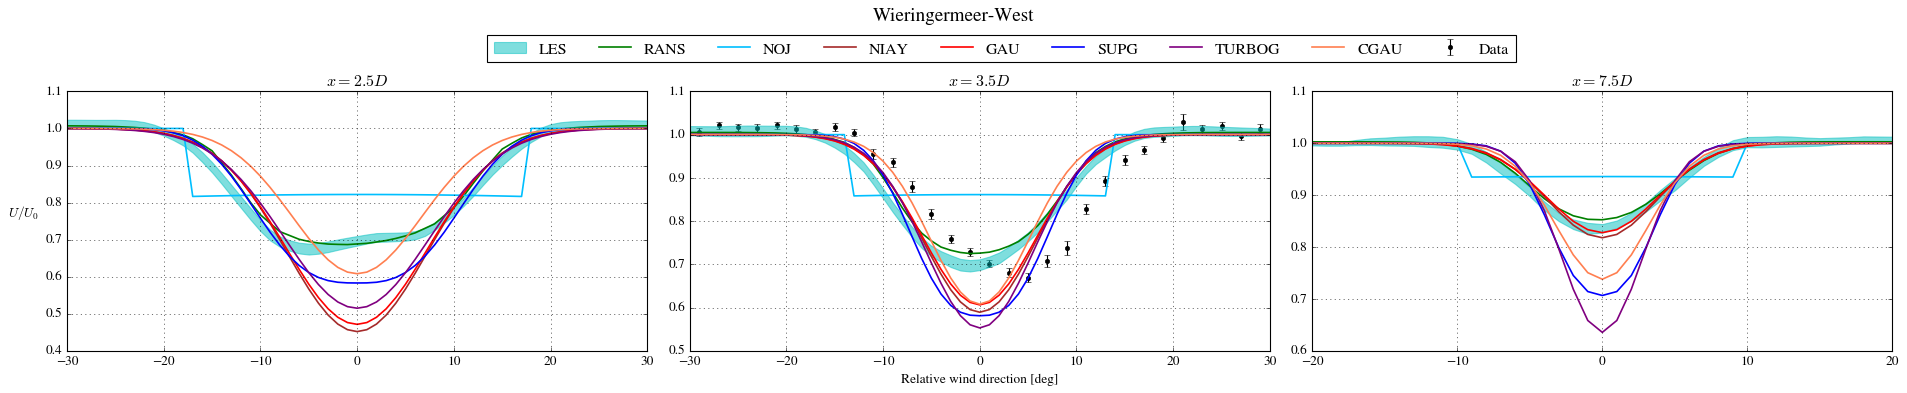

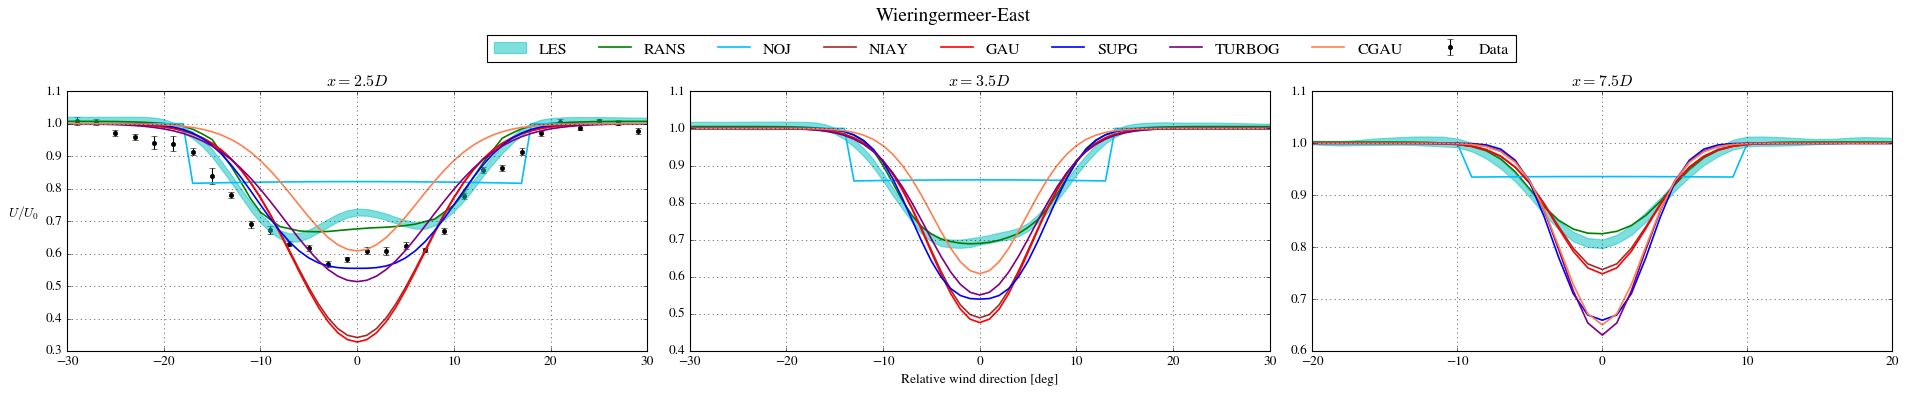

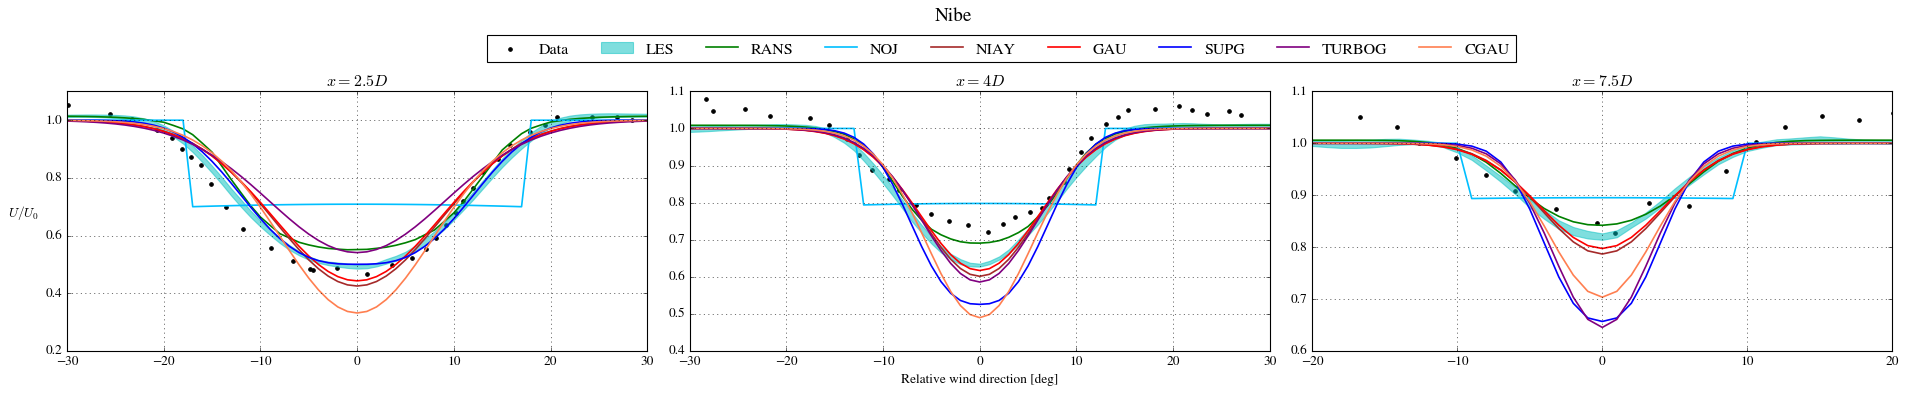

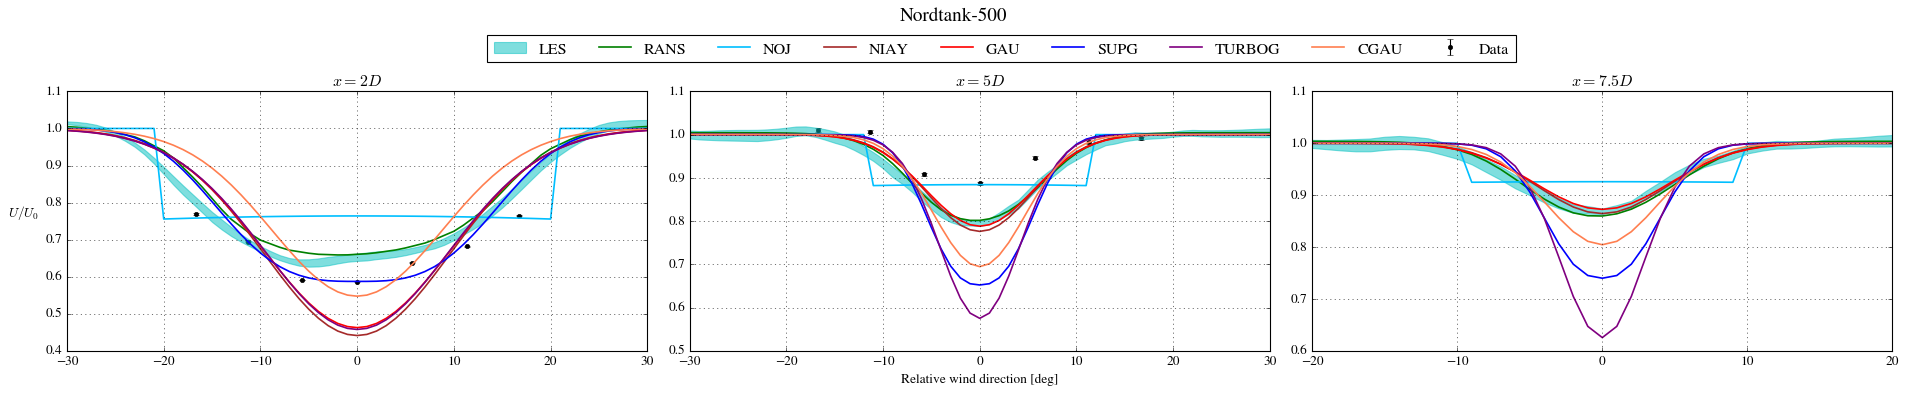

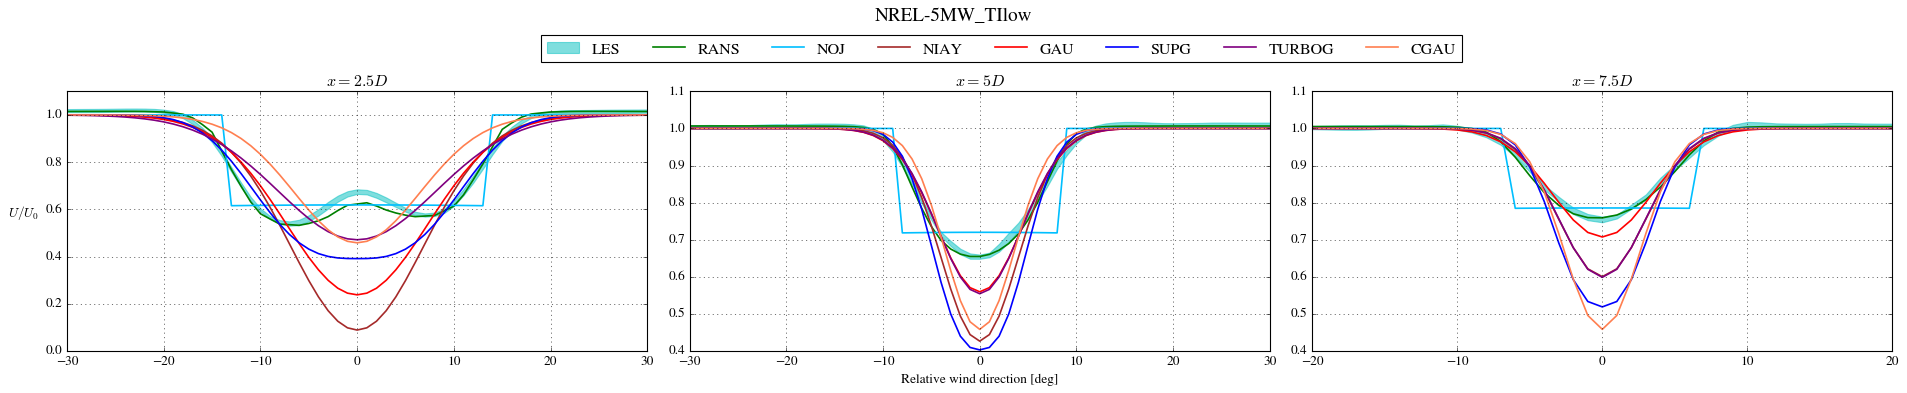

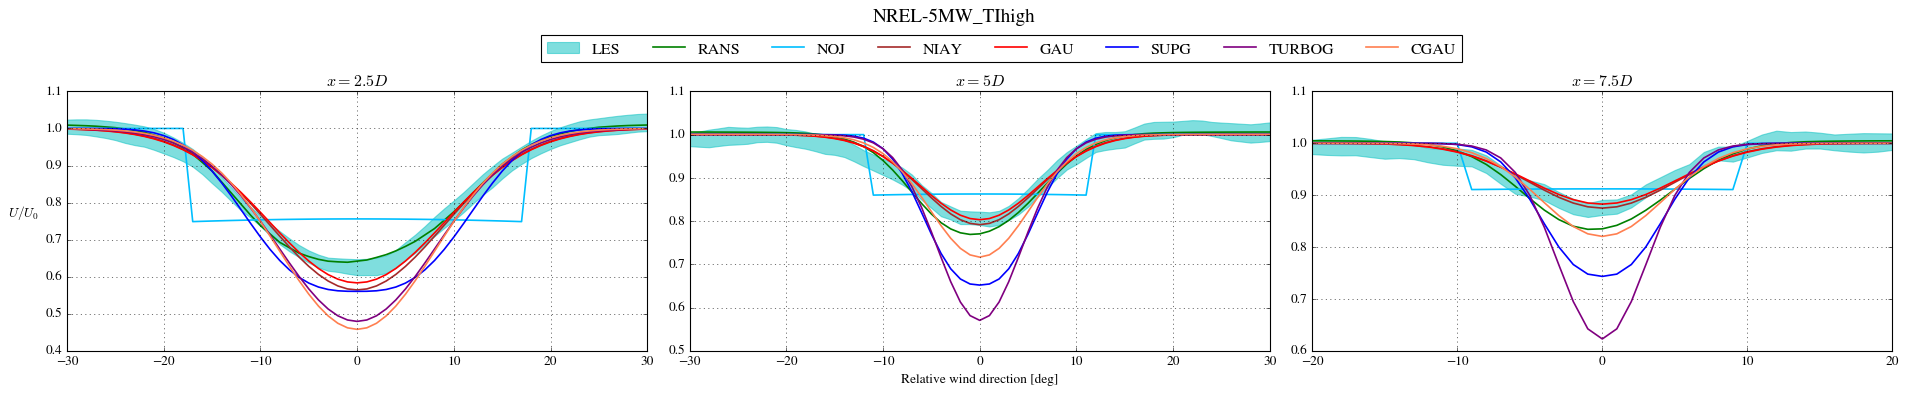

In [7]:
from py_wake.validation.benchmark.single_wake_plot_func import deficitPlotSingleWakeCases, barPlotSingleWakeCases

UdefCases = deficitPlotSingleWakeCases(SingleWakeCases, wffms, cLES, cRANS)

From the previous function, we return the integrated velocity deficit (defined as UdefCases) and plot them as a bar chart to visualize the overall contribution of each model compared to the data and LES and RANS simulations.

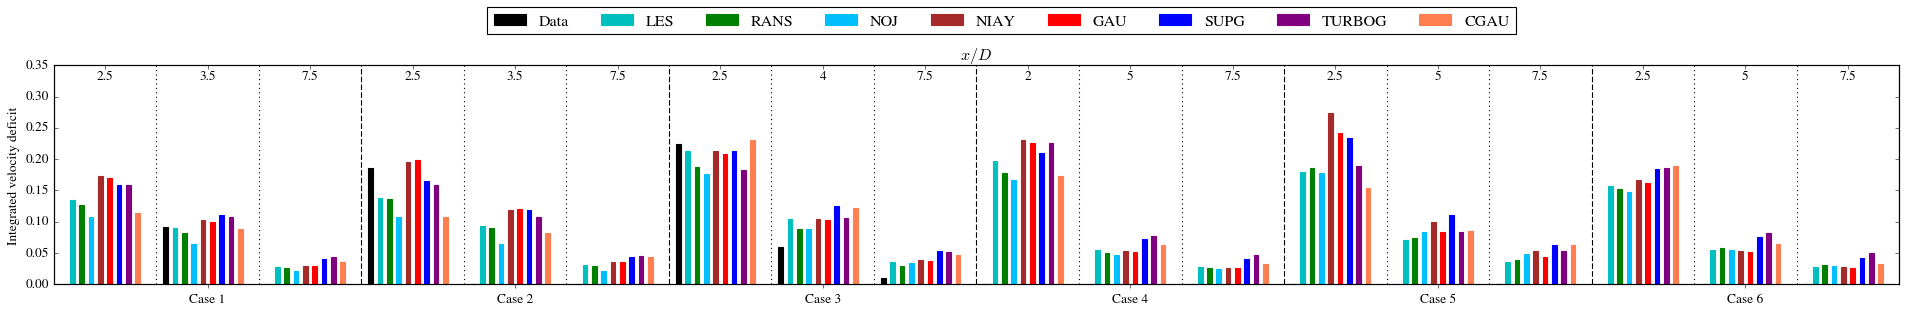

In [8]:
barPlotSingleWakeCases(SingleWakeCases, UdefCases, cLES, cRANS, wffms)

## Single Wake Case - SWiFT
---

The SWiFT Single Wake cases studied in the benchmark corresponds to:
    
| Name | $U_0$ (m/s) | $TI$ (%)| $D$ (m)| $z_H$ (m)| 
| :--- | :--- | :--- | :--- | :--- | 
| Neutral | 8.7 | 8.8 | 27 | 32.1
| Stable | 4.8 | 2.9 | 27 | 32.1
| Unstable | 6.7 | 10 | 27 | 32.1

In [9]:
from py_wake.validation.benchmark.single_wake_plot_func import plotSingleWake_SWiFT
from py_wake.examples.data.v27swift import V27SWIFT

# Import path for FUGA LUTs for each case

path_neutral = lut_path + '/SWiFT-Neutral/LUTs_Zeta0=0.00e+00_8.0_32_D27_zhub32.1_zi400_z0=0.00280000_z32.1_UL_nx2048_ny512_dx1.6875_dy0.421875.nc'
path_stable = lut_path + '/SWiFT-Stable/LUTs_Zeta0=3.50e-04_8.0_32_D27_zhub32.1_zi400_z0=0.00040000_z32.1_UL_nx2048_ny512_dx1.6875_dy0.421875.nc'
path_unstable = lut_path + '/SWiFT-Unstable/LUTs_Zeta0=-2.40e-05_8.0_32_D27_zhub32.1_zi400_z0=0.01000000_z32.1_UL_nx2048_ny512_dx1.6875_dy0.421875.nc'

# Defining the dictionary containing all the cases and their setup
StabilityCases = [
    {'name': 'neutral', 'U0': 8.7, 'TItot': 0.088, 'location': 'onshore', 'fugaPath': path_neutral,
     'xDown': [2, 3, 4, 5], 'wt': V27SWIFT()},
    {'name': 'stable', 'U0': 4.8, 'TItot': 0.029, 'location': 'onshore', 'fugaPath': path_stable, 'xDown': [2, 3, 4, 5],
     'wt': V27SWIFT()},
    {'name': 'unstable', 'U0': 6.6, 'TItot': 0.1, 'location': 'onshore', 'fugaPath': path_unstable,
     'xDown': [2, 3, 4, 5], 'wt': V27SWIFT()}
]

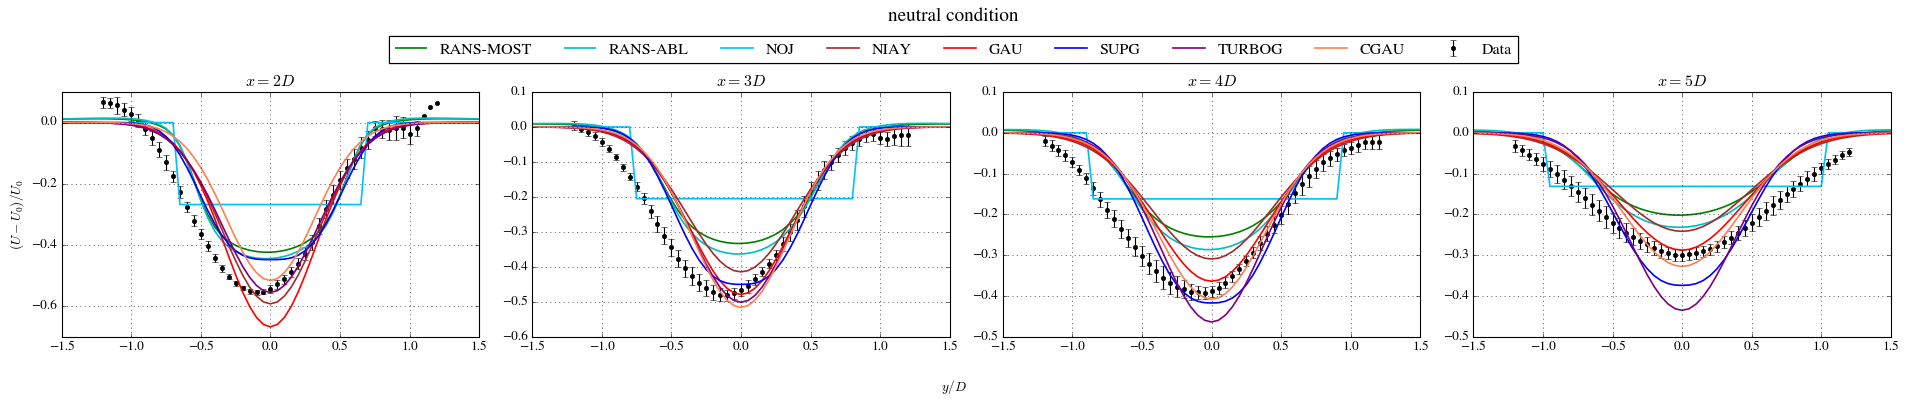

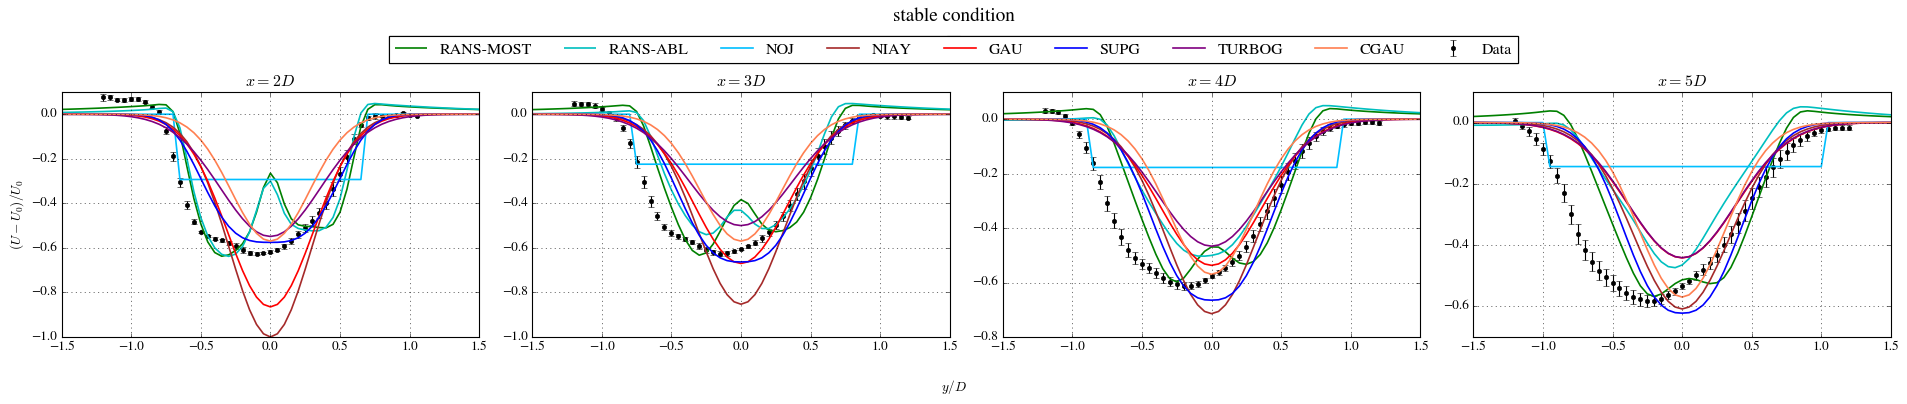

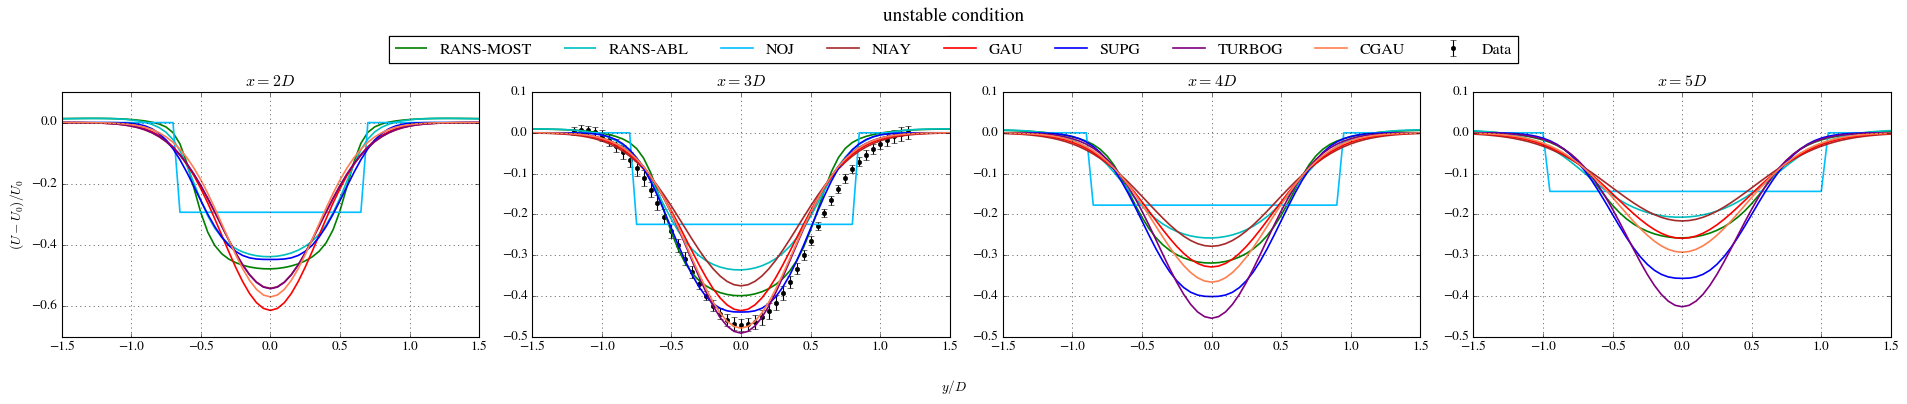

In [10]:
plotSingleWake_SWiFT(StabilityCases, wffms, cLES)

## Wind Farm Cases
---

The Wind Farm Cases studied in the benchmark correspond to:
    
| Name | $U_0$ (m/s)  | $TI$ (%) | $D$ (m) | $z_H$ (m) |
| :--- | :--- | :--- | :--- | :--- | 
| Wieringermeer | 8.35 | 9.6 | 80 | 80 | 
| Lillgrund | 9.0 | 4.8 | 92.6 | 65 | 
| Horns Rev I | 8.0 | 5.6 | 80 | 70 | 

In [11]:
from py_wake.validation.benchmark.wind_farm_plot_func import deficitPlotWFCases

import py_wake.examples.data.hornsrev1 as hornsrev1
import py_wake.examples.data.lillgrund as lillgrund
import py_wake.examples.data.ecn_wieringermeer as wieringermeer
from py_wake.site import UniformSite

In [12]:
# Import path for FUGA LUTs for each case

path_wieringermeer = lut_path + '/Wieringermeer_WF/LUTs_Zeta0=0.00e+00_8_32_D80_zhub80_zi400_z0=0.00239000_z80.0_UL_nx2048_ny512_dx20.0_dy5.0.nc'
path_lillgrund = lut_path + '/Lillgrund_WF/LUTs_Zeta0=0.00e+00_8_32_D92.6_zhub65_zi400_z0=0.00005000_z65.0_UL_nx2048_ny512_dx23.15_dy5.7875.nc'
path_hornsrev = lut_path + '/Hornsrev_WF/LUTs_Zeta0=0.00e+00_8_32_D80_zhub70_zi400_z0=0.00000100_z70.0_UL_nx2048_ny512_dx20.0_dy5.0.nc'

In [13]:
# Defining the dictionary containing all of the cases and their setup

WFcases = [{'name': 'Wieringermeer', 'U0': 8.35, 'TItot': 0.096, 'wt': wieringermeer.N80(),
            'wt_x': wieringermeer.wt_x, 'wt_y': wieringermeer.wt_y,
            'site': UniformSite(p_wd=[1], ti=0.096 / 0.8, ws=8.35), 'location': 'onshore',
            'plots': [{'name': 'Row', 'wd': 275.0, 'wts': [0, 1, 2, 3, 4]}], 'fugaPath': path_wieringermeer},
           {'name': 'Lillgrund', 'U0': 9.0, 'TItot': 0.048, 'wt': lillgrund.SWT23(),
            'wt_x': lillgrund.wt_x, 'wt_y': lillgrund.wt_y,
            'site': lillgrund.LillgrundSite(), 'location': 'offshore',
            'plots': [{'name': 'RowB', 'wd': 222.0, 'wts': [14, 13, 12, 11, 10, 9, 8, 7]},
                      {'name': 'RowD', 'wd': 222.0, 'wts': [29, 28, 27, np.nan, 26, 25, 24, 23]},
                      {'name': 'RowB', 'wd': 207.0, 'wts': [14, 13, 12, 11, 10, 9, 8, 7]},
                      {'name': 'RowD', 'wd': 207.0, 'wts': [29, 28, 27, np.nan, 26, 25, 24, 23]},
                      {'name': 'Row6', 'wd': 120.0, 'wts': [2, 9, 17, 25, 32, 37, 42, 46]},
                      {'name': 'Row4', 'wd': 120.0, 'wts': [4, 11, 19, np.nan, np.nan, 39, 44]},
                      {'name': 'Row6', 'wd': 105.0, 'wts': [2, 9, 17, 25, 32, 37, 42, 46]},
                      {'name': 'Row4', 'wd': 105.0, 'wts': [4, 11, 19, np.nan, np.nan, 39, 44]},
                      {'name': 'WFeff'}], 'fugaPath': path_lillgrund},
           {'name': 'Hornsrev1', 'U0': 8.0, 'TItot': 0.056, 'wt': hornsrev1.HornsrevV80(),
            'wt_x': hornsrev1.wt_x, 'wt_y': hornsrev1.wt_y,
            'site': hornsrev1.Hornsrev1Site(), 'location': 'offshore',
            'plots': [{'name': 'InnerRowMean', 'wd': 270.0,
                       'wts': np.linspace(0, 79, 80).reshape(10, 8)[:, 1:7].flatten().tolist()}],
            'fugaPath': path_hornsrev}
           ]

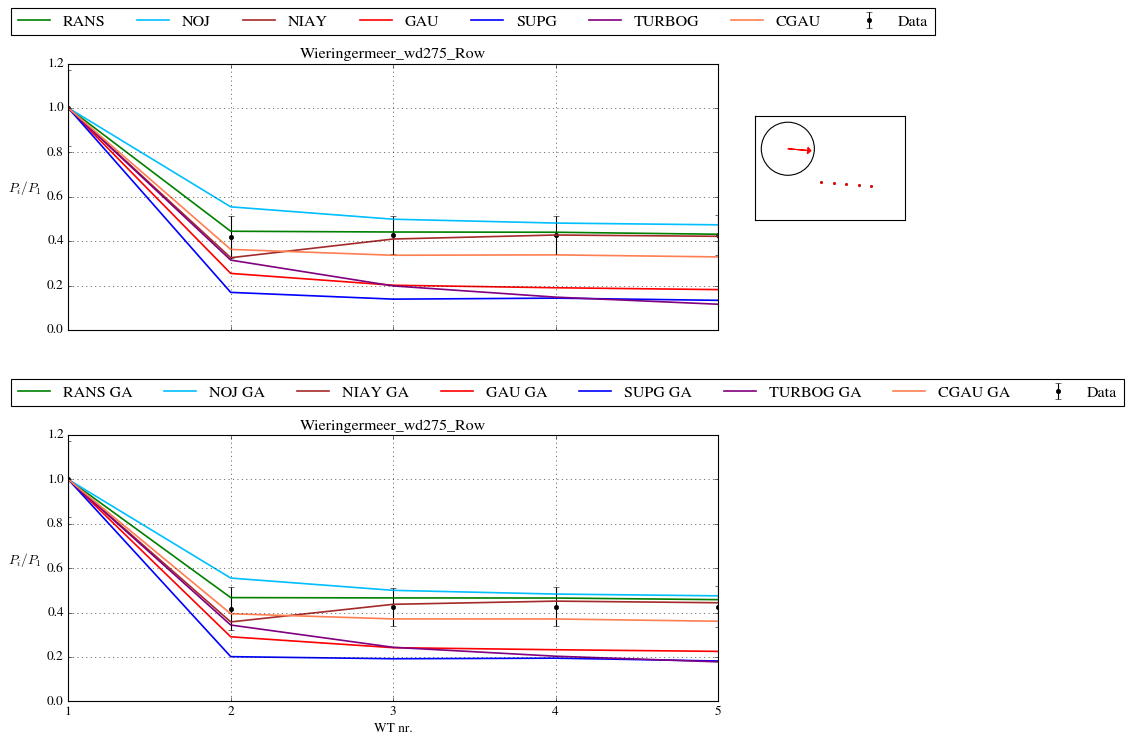

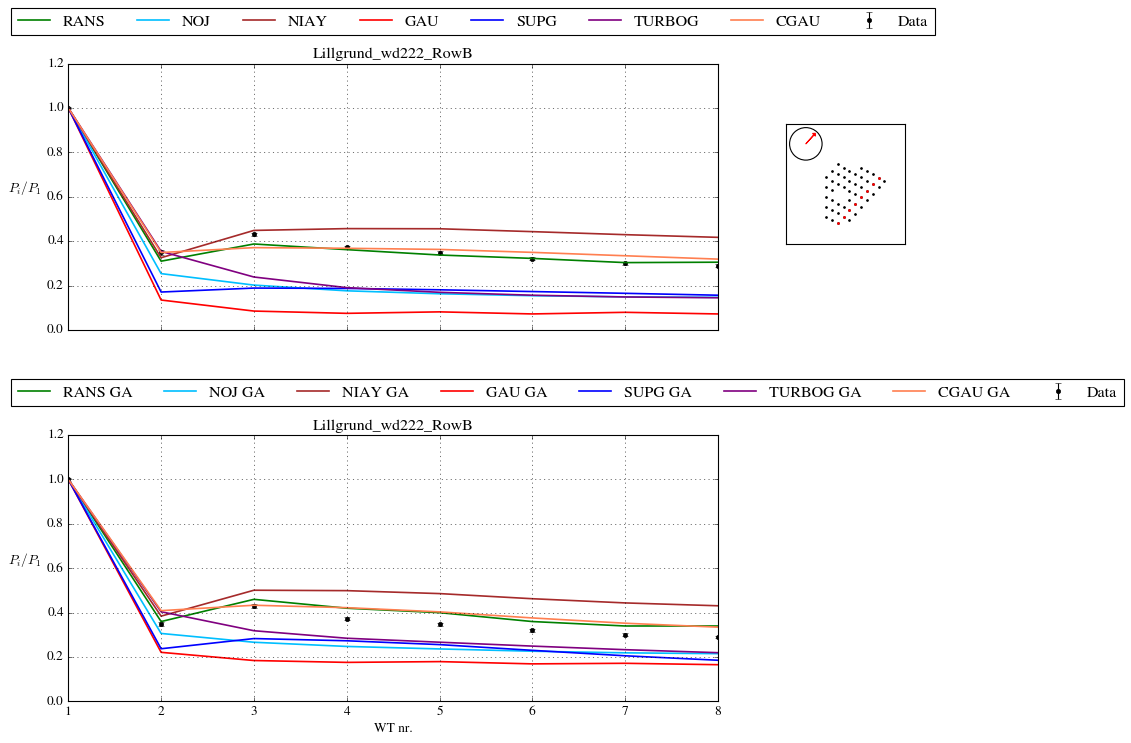

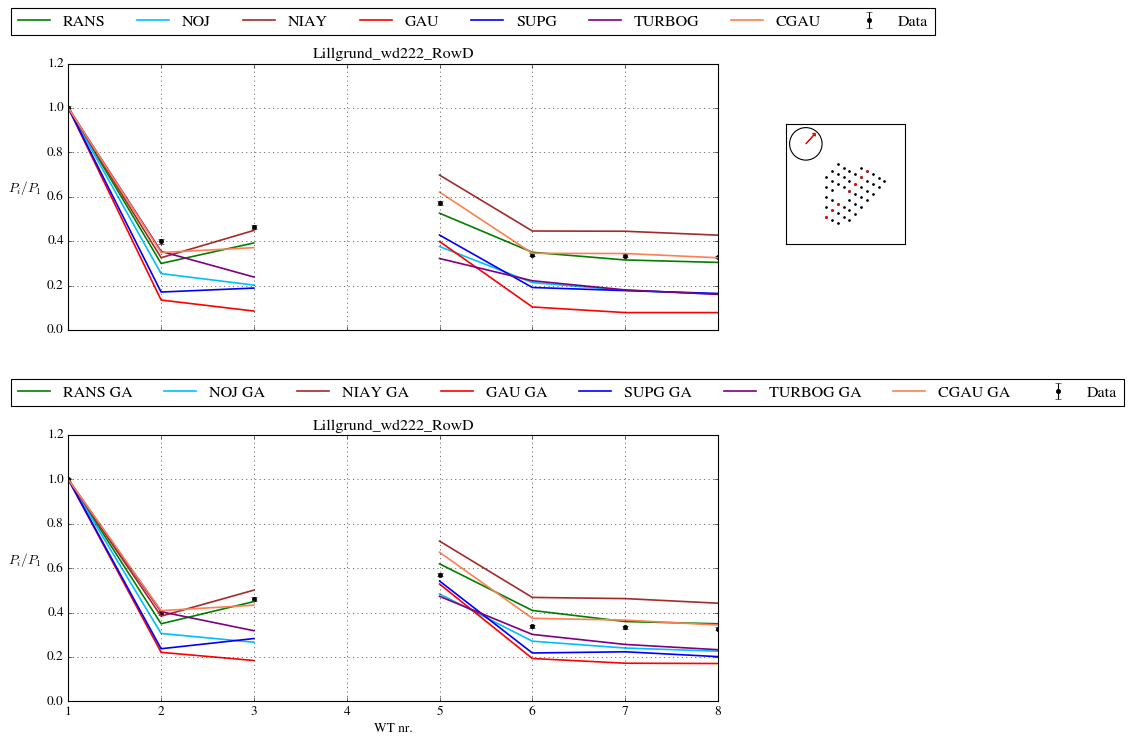

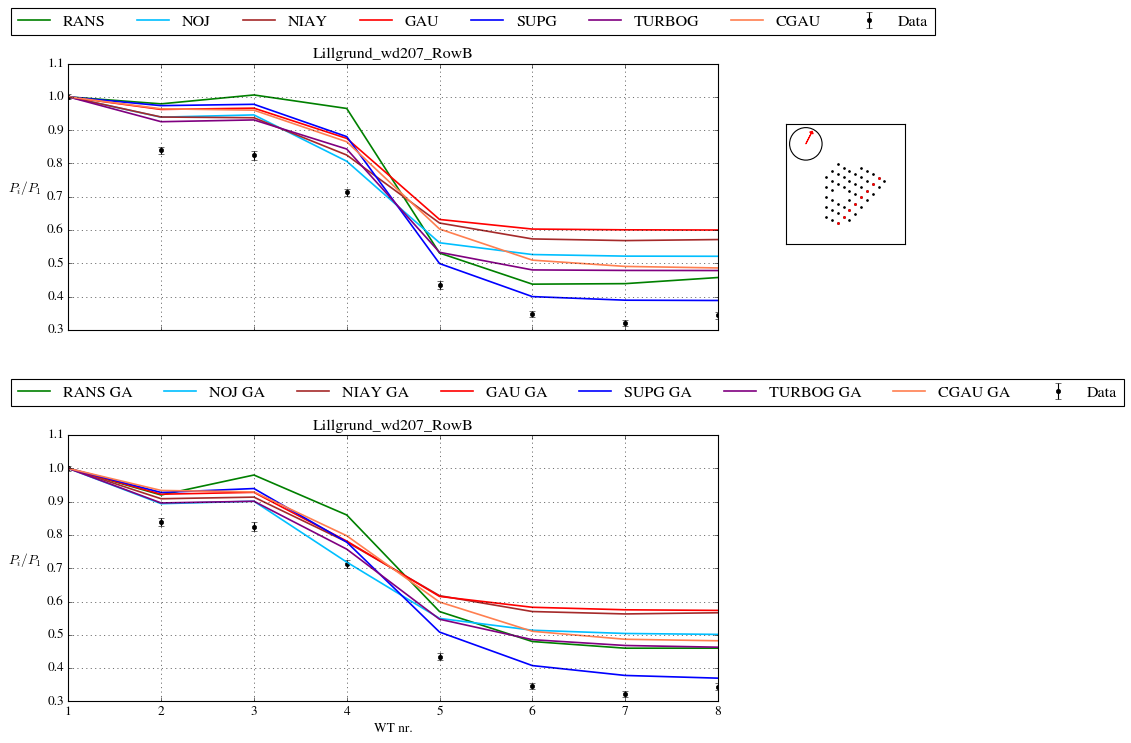

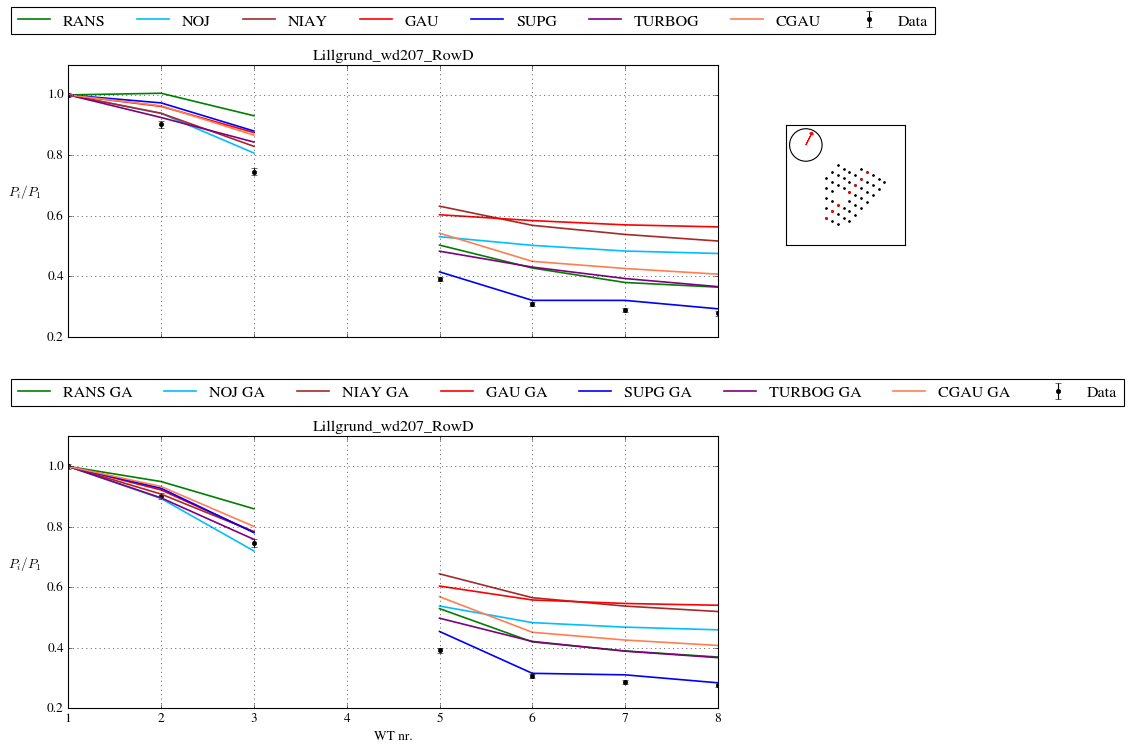

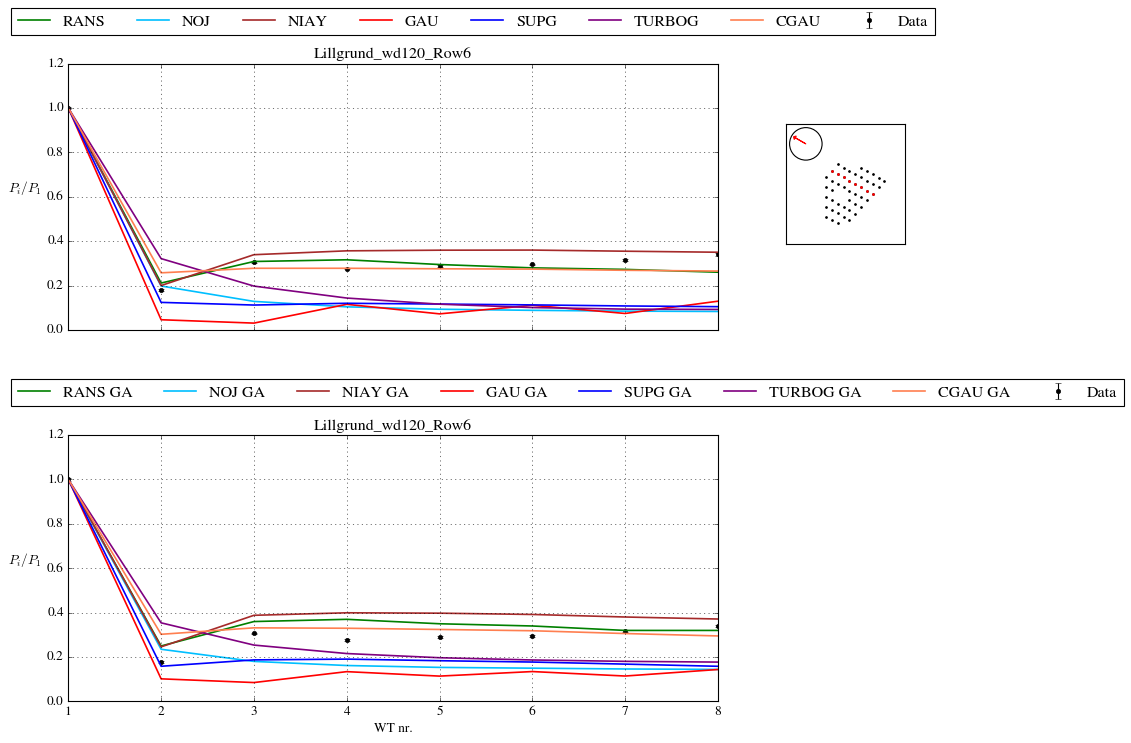

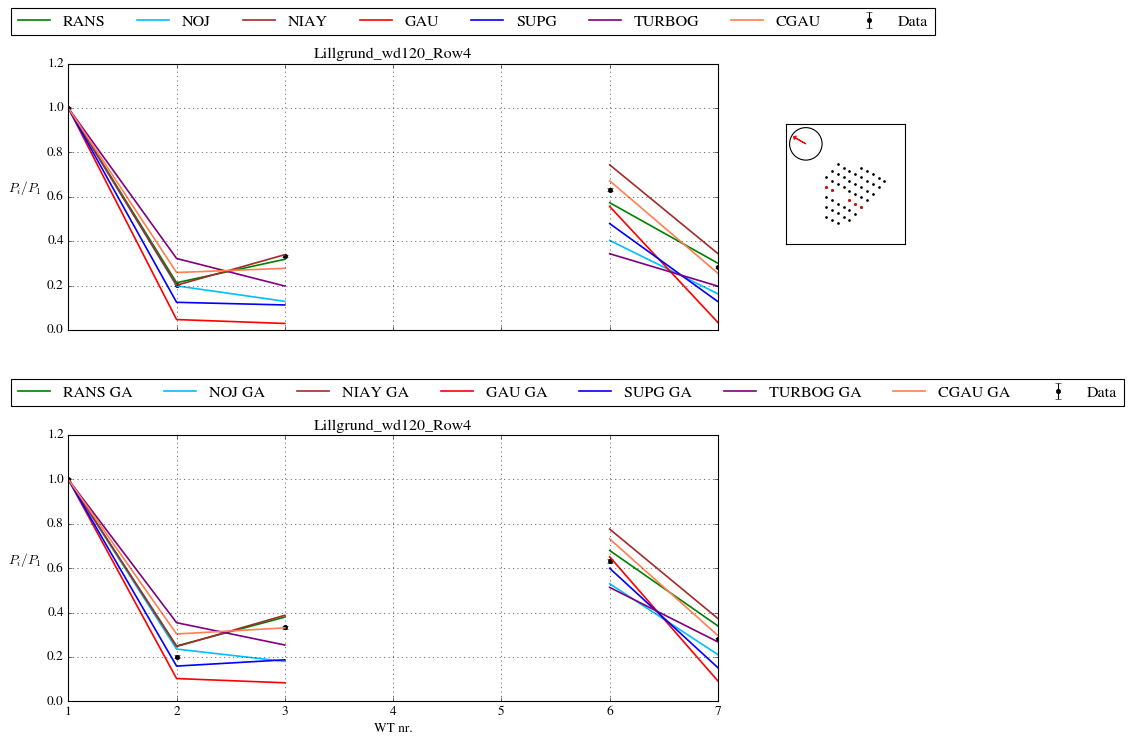

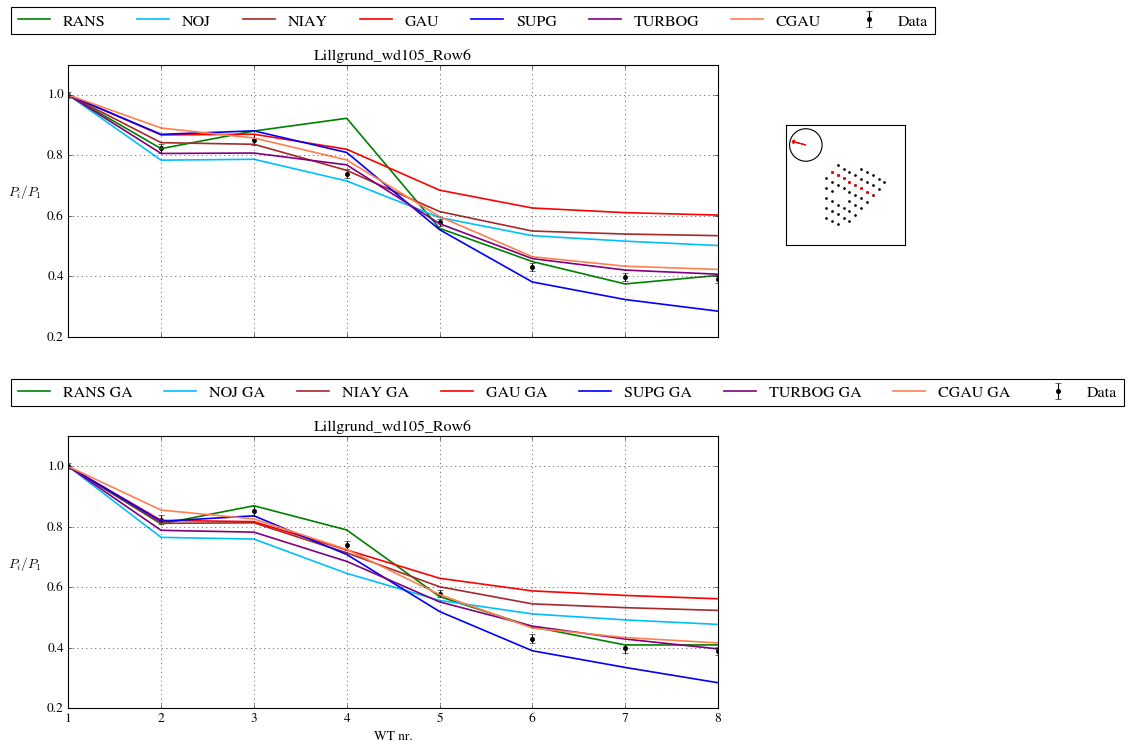

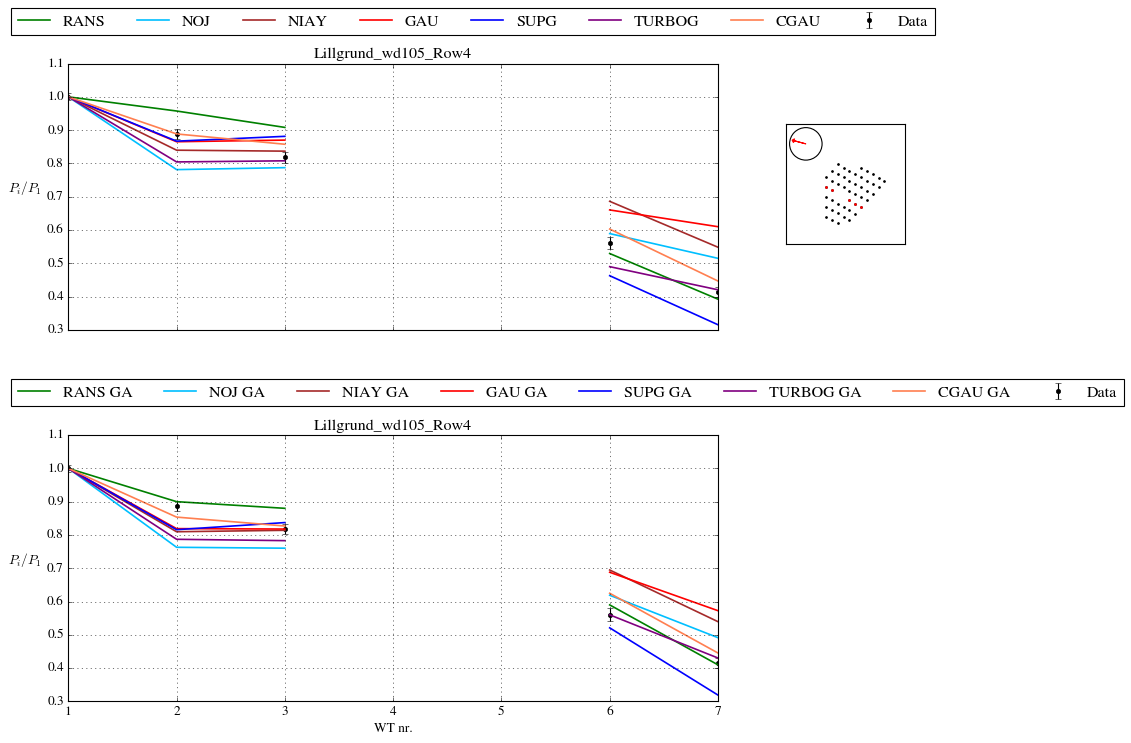

WFeff NOJ 0.62276915979575
WFeff NIAY 0.7061366963480116
WFeff GAU 0.6425594927379984
WFeff SUPG 0.6037832157377535
WFeff TURBOG 0.6330638883330192
WFeff CGAU 0.6756439009489106
WFeff RANS 0.6393736000000001
WFeff DATA 0.6592924166666666


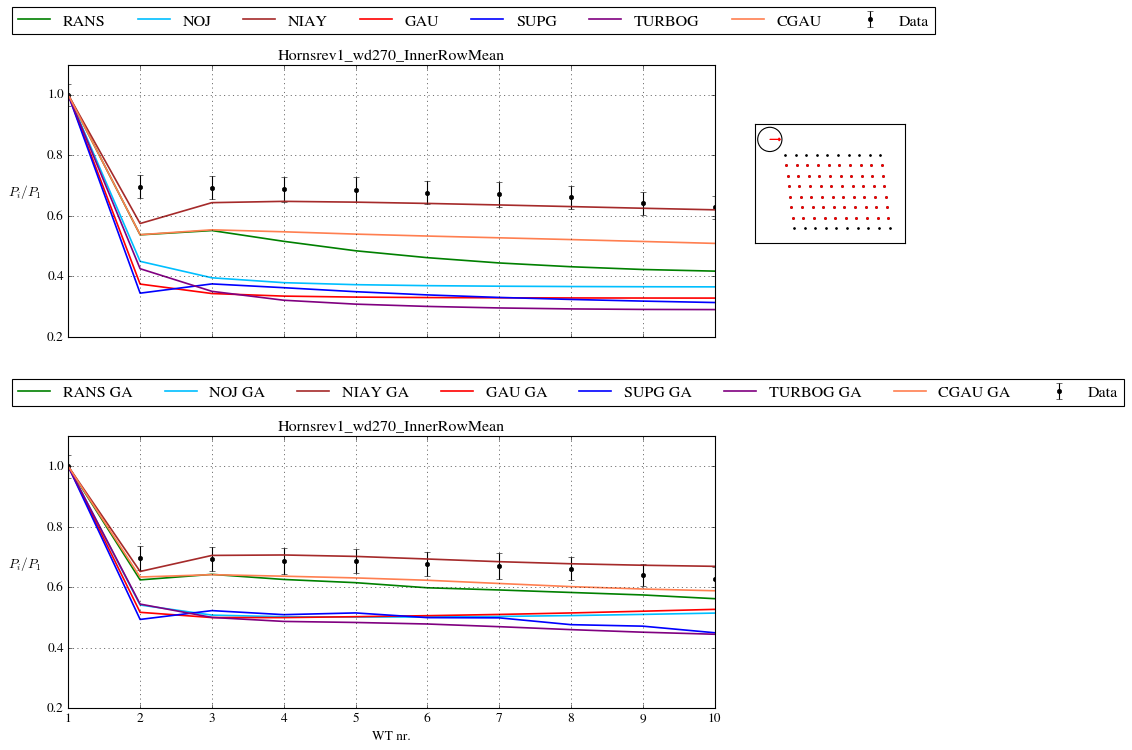

In [14]:
deficitPlotWFCases(WFcases, wffms, cLES, cRANS)

## Farm to Farm Interaction
---

Nysted, Rødsand II, SCADA data, diameter used as references corresponds to  Rødsand II's wind turbine, $D = 93 m $.

| Name | $U_0$ (m/s)  | $TI$ (%) | $z_H$ (m) |
| :--- | :--- | :--- | :--- |  
| Nysted + Rødsand | 8 | 7 | 68.5 | 

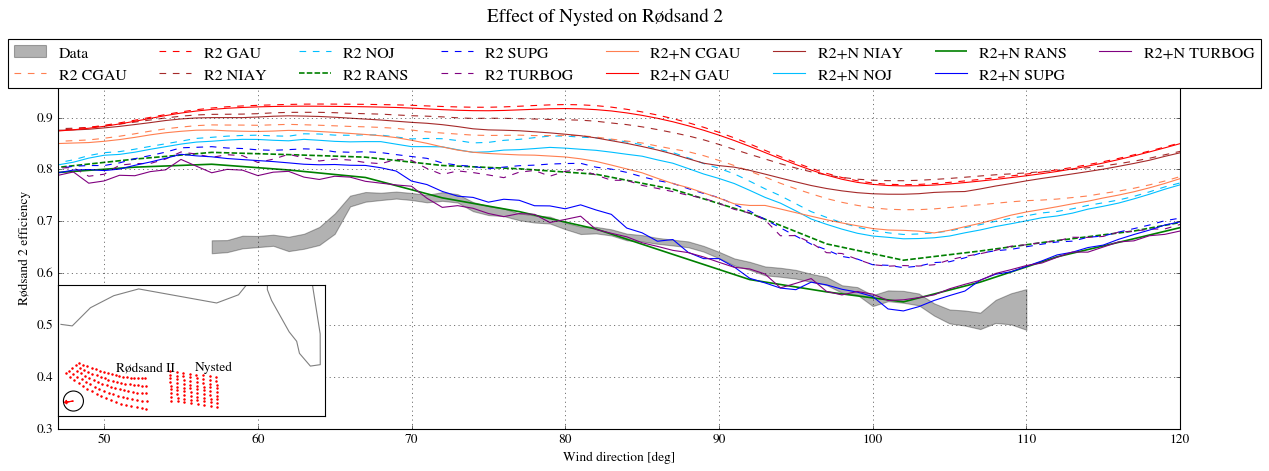

In [15]:
from py_wake.validation.benchmark.f2f_plot_func import plotF2FCase

plotF2FCase(wffms, plotGAonly=False, weibull_weight_ws=False)
# models are normalized to the nominal power at U0 (no wake)
# RANS data is already normalized and GA @5 deg. (10.1002/we.1804)
# 10.1088/1742-6596/625/1/012008

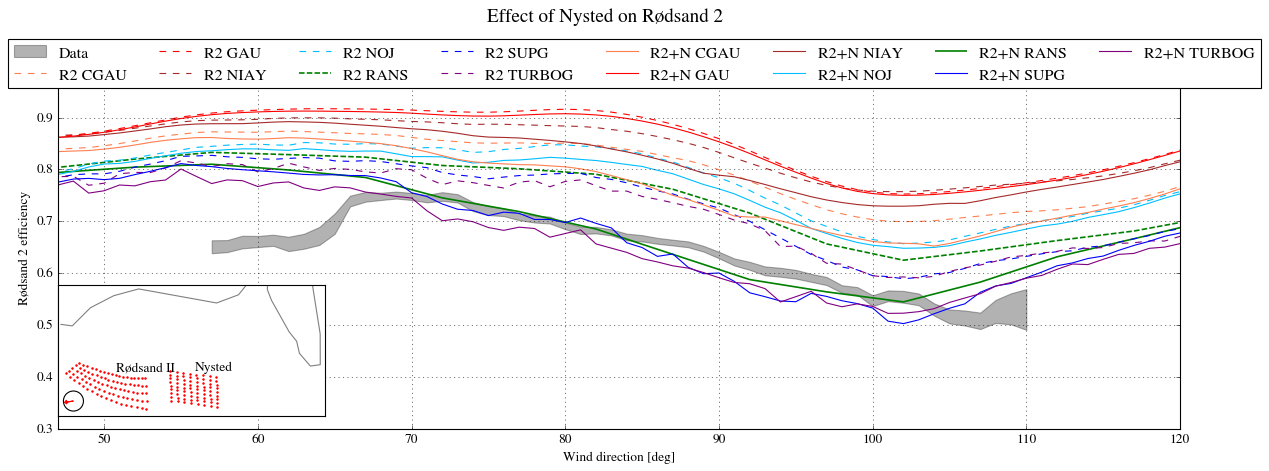

In [16]:
plotF2FCase(wffms, plotGAonly=False, weibull_weight_ws=True)

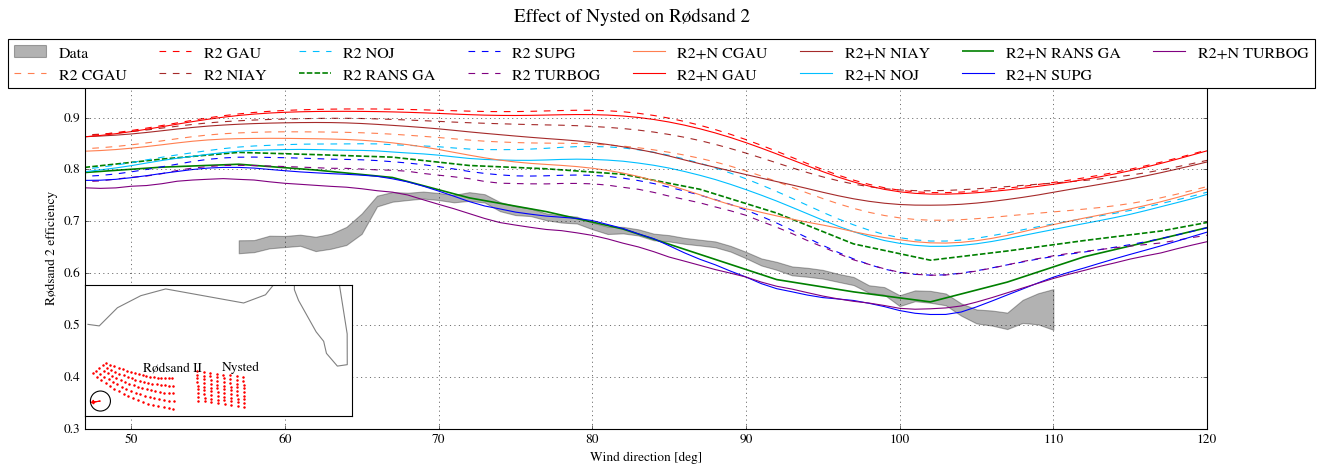

In [17]:
plotF2FCase(wffms, plotGAonly=True, weibull_weight_ws=True)